**Team Insights | Enrollment No :- 240840116047**

**Zomato Restaurants Analysis (Bangalore) | Data cleaning and statistical analysis**

**Step 1 : Import Libraries**

In [ ]:
# import numpy, pandas, matplotlib, seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Step 2 : Load and inspect Dataset**

In [ ]:
# Load the raw Zomato dataset (upload zomato.csv to Colab first)
df = pd.read_csv('zomato.csv', encoding='latin-1')
df

,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur
...,...,...,...,...,...,...,...,...,...,...,...,...
7100,7100,7100,Zoey's,Cafe,4.3,894,600.0,Yes,No,"Cafe, Italian, Continental, Burger",Bellandur,Sarjapur Road
7101,7101,7101,ZOROY Luxury Chocolate,Dessert Parlor,4.0,68,250.0,Yes,No,Desserts,Brigade Road,Church Street
7102,7102,7102,Zu's Doner Kebaps,"Takeaway, Delivery",3.7,33,350.0,No,No,"Turkish, Fast Food, Biryani, Chinese",Malleshwaram,RT Nagar
7103,7103,7103,Zyara,Casual Dining,3.8,191,650.0,Yes,No,"North Indian, Mughlai, Chinese",Kammanahalli,HBR Layout


In [ ]:
# Display the first five records
df.head()

,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


In [ ]:
# Display the number of rows and columns
df.shape

(7105, 12)

In [ ]:
# Display information about columns and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7105 entries, 0 to 7104
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0.1           7105 non-null   int64  
 1   Unnamed: 0             7105 non-null   int64  
 2   restaurant name        7105 non-null   str    
 3   restaurant type        7105 non-null   str    
 4   rate (out of 5)        7037 non-null   float64
 5   num of ratings         7105 non-null   int64  
 6   avg cost (two people)  7048 non-null   float64
 7   online_order           7105 non-null   str    
 8   table booking          7105 non-null   str    
 9   cuisines type          7105 non-null   str    
 10  area                   7105 non-null   str    
 11  local address          7105 non-null   str    
dtypes: float64(2), int64(3), str(7)
memory usage: 666.2 KB


In [ ]:
# Display basic statistical information
df.describe()

,Unnamed: 0.1,Unnamed: 0,rate (out of 5),num of ratings,avg cost (two people)
count,7105.000000,7105.000000,7037.000000,7105.000000,7048.000000
mean,3552.000000,3552.000000,3.514253,188.921042,540.286464
std,2051.181164,2051.181164,0.463249,592.171049,462.902305
min,0.000000,0.000000,1.800000,1.000000,40.000000
25%,1776.000000,1776.000000,3.200000,16.000000,300.000000
50%,3552.000000,3552.000000,3.500000,40.000000,400.000000
75%,5328.000000,5328.000000,3.800000,128.000000,600.000000
max,7104.000000,7104.000000,4.900000,16345.000000,6000.000000


**Step 3 : Data Cleaning**

In [ ]:
# Drop the 2 unnamed index columns
df = df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])
df.shape

(7105, 10)

In [ ]:
# Check missing values in each column
df.isnull().sum()

restaurant name           0
restaurant type           0
rate (out of 5)          68
num of ratings            0
avg cost (two people)    57
online_order              0
table booking             0
cuisines type             0
area                      0
local address             0
dtype: int64

In [ ]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
# Remove rows with missing rating or cost (121 rows)
df = df.dropna()
df = df.reset_index(drop=True)
df.shape

(6984, 10)

In [ ]:
# Confirm no missing values are left
df.isnull().sum()

restaurant name          0
restaurant type          0
rate (out of 5)          0
num of ratings           0
avg cost (two people)    0
online_order             0
table booking            0
cuisines type            0
area                     0
local address            0
dtype: int64

**Step 4 : Create new columns**

In [ ]:
# Primary cuisine = first cuisine in the list
df['primary cuisine'] = df['cuisines type'].str.split(',').str[0].str.strip()
df[['cuisines type', 'primary cuisine']].head()

,cuisines type,primary cuisine
0,Fast Food,Fast Food
1,"Fast Food, Beverages",Fast Food
2,"Cafe, Beverages",Cafe
3,"Biryani, Mughlai, Chinese",Biryani
4,"BBQ, Continental, North Indian, Chinese, Bever...",BBQ


In [ ]:
# Type group = 5 most common restaurant types, all others become 'Other'
top5 = df['restaurant type'].value_counts().head(5).index
df['type group'] = np.where(df['restaurant type'].isin(top5), df['restaurant type'], 'Other')
df['type group'].value_counts()

type group
Quick Bites           2784
Casual Dining         1620
Other                 1556
Cafe                   395
Delivery               346
Takeaway, Delivery     283
Name: count, dtype: int64

In [ ]:
# Cost range and its order (1 to 7)
bins = [0, 200, 400, 600, 800, 1000, 1500, np.inf]
labels = ['≤200', '201-400', '401-600', '601-800', '801-1000', '1001-1500', '>1500']
df['cost range'] = pd.cut(df['avg cost (two people)'], bins=bins, labels=labels)
df['cost range order'] = df['cost range'].cat.codes + 1
df[['avg cost (two people)', 'cost range', 'cost range order']].head()

,avg cost (two people),cost range,cost range order
0,200.0,≤200,1
1,400.0,201-400,2
2,400.0,201-400,2
3,550.0,401-600,3
4,700.0,601-800,4


In [ ]:
# Final cleaned dataset
print(df.shape)
df.head()

(6984, 14)


,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address,primary cuisine,type group,cost range,cost range order
0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur,Fast Food,Quick Bites,≤200,1
1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR,Fast Food,Quick Bites,201-400,2
2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road,Cafe,Cafe,201-400,2
3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli,Biryani,Casual Dining,401-600,3
4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur,BBQ,Casual Dining,601-800,4


**Step 5 : Statistical information**

In [ ]:
# Basic statistics of the cleaned data
df.describe()

,rate (out of 5),num of ratings,avg cost (two people),cost range order
count,6984.000000,6984.000000,6984.000000,6984.000000
mean,3.514304,190.928837,542.544244,2.789948
std,0.463489,596.717894,464.266828,1.548160
min,1.800000,1.000000,40.000000,1.000000
25%,3.200000,15.000000,300.000000,2.000000
50%,3.500000,40.000000,400.000000,2.000000
75%,3.800000,130.000000,600.000000,3.000000
max,4.900000,16345.000000,6000.000000,7.000000


In [ ]:
# Mean and median of cost for two
print('Mean   :', df['avg cost (two people)'].mean())
print('Median :', df['avg cost (two people)'].median())

Mean   : 542.5442439862543
Median : 400.0


In [ ]:
# Average rating of all restaurants
df['rate (out of 5)'].mean()

np.float64(3.5143041237113404)

In [ ]:
# Online order count and percentage
print(df['online_order'].value_counts())
print(df['online_order'].value_counts(normalize=True) * 100)

online_order
Yes    3721
No     3263
Name: count, dtype: int64
online_order
Yes    53.278923
No     46.721077
Name: proportion, dtype: float64


In [ ]:
# Table booking count and percentage
print(df['table booking'].value_counts())
print(df['table booking'].value_counts(normalize=True) * 100)

table booking
No     6240
Yes     744
Name: count, dtype: int64
table booking
No     89.347079
Yes    10.652921
Name: proportion, dtype: float64


In [ ]:
# Average rating by table booking
df.groupby('table booking')['rate (out of 5)'].mean()

table booking
No     3.452099
Yes    4.036022
Name: rate (out of 5), dtype: float64

In [ ]:
# Average rating by cost range
df.groupby('cost range', observed=True)['rate (out of 5)'].mean()

cost range
≤200         3.390871
201-400      3.419400
401-600      3.468257
601-800      3.606019
801-1000     3.714478
1001-1500    3.988509
>1500        4.087747
Name: rate (out of 5), dtype: float64

In [ ]:
# Number of restaurants and average rating by type group
df.groupby('type group')['rate (out of 5)'].agg(['count', 'mean'])

,count,mean
type group,,
Cafe,395,3.693671
Casual Dining,1620,3.594691
Delivery,346,3.380925
Other,1556,3.659190
Quick Bites,2784,3.400647
"Takeaway, Delivery",283,3.288339


In [ ]:
# Top 10 areas by number of restaurants
df['area'].value_counts().head(10)

area
Byresandra,Tavarekere,Madiwala    794
Bannerghatta Road                 552
Brookefield                       477
Brigade Road                      463
Indiranagar                       450
Electronic City                   402
Malleshwaram                      401
Kalyan Nagar                      379
Bellandur                         359
Banashankari                      359
Name: count, dtype: int64

In [ ]:
# Top 8 primary cuisines by number of restaurants
df['primary cuisine'].value_counts().head(8)

primary cuisine
North Indian    1918
South Indian     824
Chinese          451
Cafe             443
Biryani          403
Fast Food        382
Continental      248
Bakery           227
Name: count, dtype: int64

In [ ]:
# Correlation between numerical columns
df[['rate (out of 5)', 'num of ratings', 'avg cost (two people)']].corr()

,rate (out of 5),num of ratings,avg cost (two people)
rate (out of 5),1.000000,0.381366,0.375916
num of ratings,0.381366,1.000000,0.339738
avg cost (two people),0.375916,0.339738,1.000000


**Step 6 : Create charts**

**Chart 1 : Histogram of rating**

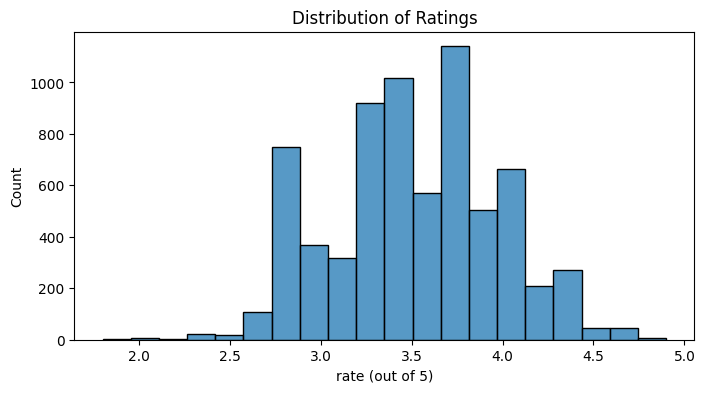

In [ ]:
# Distribution of ratings
plt.figure(figsize=(8,4))
sns.histplot(df['rate (out of 5)'], bins=20)
plt.title('Distribution of Ratings')
plt.show()

**Chart 2 : Box plot of cost for two**

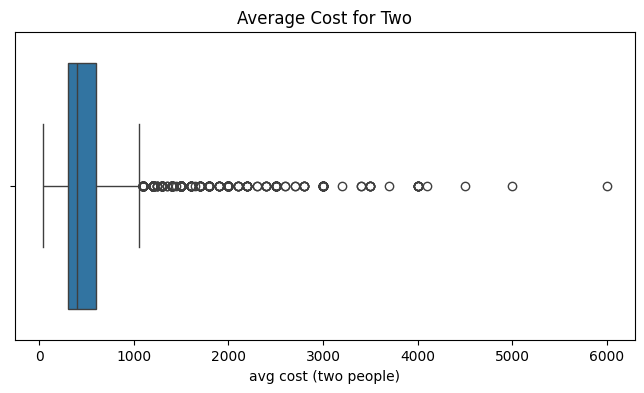

In [ ]:
# Box plot to see the cost outliers
plt.figure(figsize=(8,4))
sns.boxplot(x=df['avg cost (two people)'])
plt.title('Average Cost for Two')
plt.show()

**Chart 3 : Average rating by cost range**

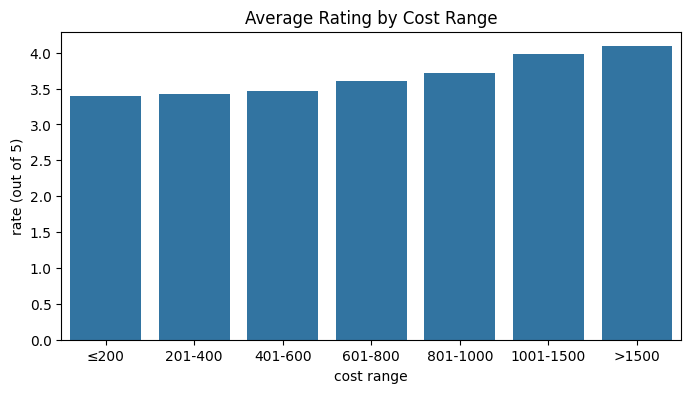

In [ ]:
# Bar chart of average rating for each cost range
plt.figure(figsize=(8,4))
sns.barplot(x='cost range', y='rate (out of 5)', data=df, errorbar=None)
plt.title('Average Rating by Cost Range')
plt.show()

**Chart 4 : Average rating by table booking**

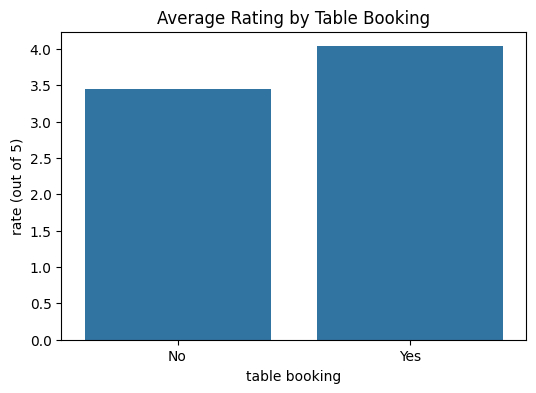

In [ ]:
# Bar chart of average rating with and without table booking
plt.figure(figsize=(6,4))
sns.barplot(x='table booking', y='rate (out of 5)', data=df, errorbar=None)
plt.title('Average Rating by Table Booking')
plt.show()

**Chart 5 : Restaurants by type group**

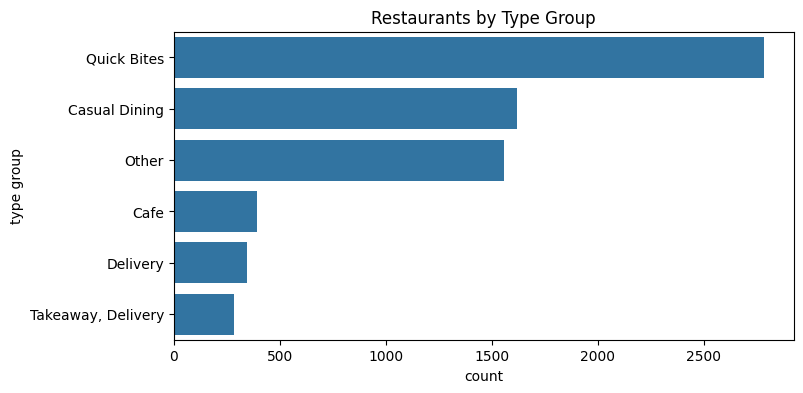

In [ ]:
# Count of restaurants in each type group
plt.figure(figsize=(8,4))
sns.countplot(y='type group', data=df, order=df['type group'].value_counts().index)
plt.title('Restaurants by Type Group')
plt.show()

**Chart 6 : Top 10 areas**

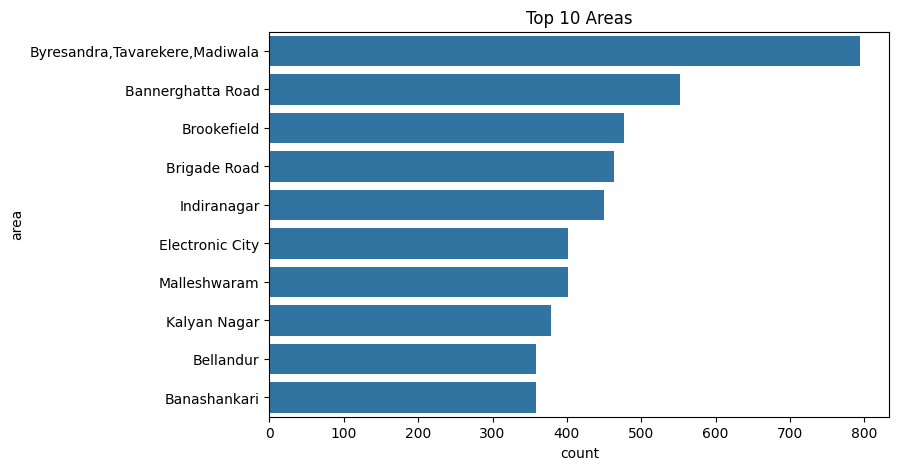

In [ ]:
# Top 10 areas by number of restaurants
plt.figure(figsize=(8,5))
sns.countplot(y='area', data=df, order=df['area'].value_counts().head(10).index)
plt.title('Top 10 Areas')
plt.show()

**Chart 7 : Top 8 cuisines**

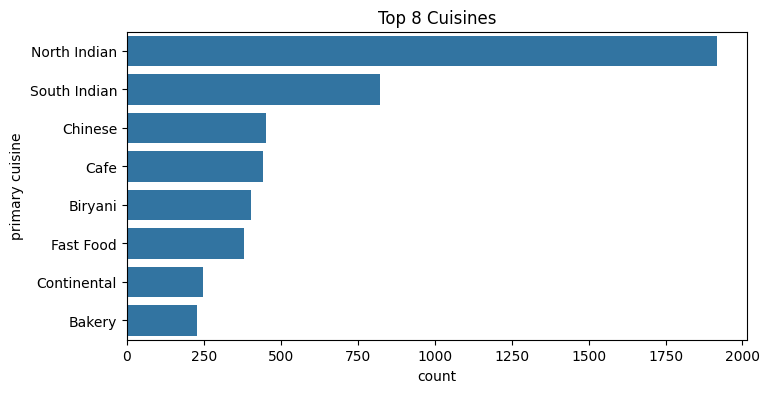

In [ ]:
# Top 8 primary cuisines by number of restaurants
plt.figure(figsize=(8,4))
sns.countplot(y='primary cuisine', data=df, order=df['primary cuisine'].value_counts().head(8).index)
plt.title('Top 8 Cuisines')
plt.show()

**Chart 8 : Online ordering**

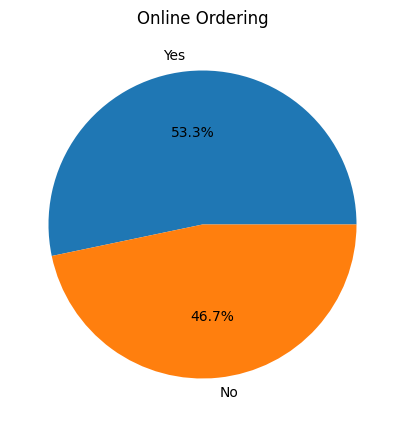

In [ ]:
# Pie chart of restaurants with and without online ordering
df['online_order'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(5,5))
plt.title('Online Ordering')
plt.ylabel('')
plt.show()

**Chart 9 : Heatmap of correlation**

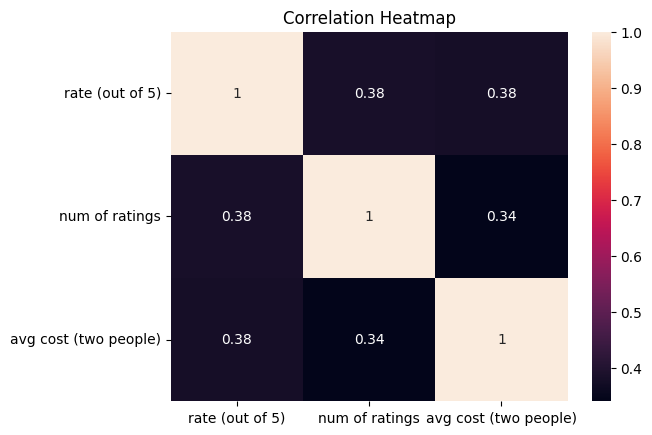

In [ ]:
# Heatmap of numerical columns
sns.heatmap(df[['rate (out of 5)', 'num of ratings', 'avg cost (two people)']].corr(), annot=True)
plt.title('Correlation Heatmap')
plt.show()

**Step 7 : What we have observed from the data**

- The raw data had 7,105 restaurants and 12 columns, including 2 unnamed index columns.
- 125 values were missing (68 ratings and 57 costs), affecting 121 restaurants (about 1.7%). We removed them, leaving 6,984 restaurants. There were no duplicate rows.
- The data covers 30 areas of Bangalore. The average rating is 3.51 out of 5.
- Cost for two is right-skewed: the median is ₹400 but the mean is about ₹543, because a few very expensive restaurants pull the average up (box plot).
- 74% of restaurants list more than one cuisine (2,175 different combinations), so we used the first cuisine as the primary cuisine.
- North Indian is the most common cuisine (27% of restaurants), followed by South Indian (12%) and Chinese (6%).
- Quick Bites is the biggest restaurant type (40%), followed by Casual Dining (23%).
- Byresandra, Tavarekere, Madiwala has the most restaurants (794), followed by Bannerghatta Road (552) and Brookefield (477).
- Only 53% of restaurants take online orders and only 11% offer table booking.
- 58% of restaurants have fewer than 50 ratings.
- Rating has a weak positive correlation (0.38) with both cost and number of ratings.

**Step 8 : Insights**

1. **Higher price means higher rating.** Average rating rises steadily from 3.39 (up to ₹200) to 4.09 (above ₹1,500). Budget restaurants get the lowest ratings.
2. **Table booking is linked to better ratings.** Restaurants with table booking average 4.04 against 3.45 without it. The gap stays at about 0.3 to 0.4 even inside the same price range, so it is not only a price effect.
3. **Quick Bites rate below average.** They are 40% of all restaurants but average only 3.40, while Cafes average 3.69. Delivery (3.38) and Takeaway, Delivery (3.29) are the lowest.
4. **Location matters.** Among areas with 150 or more restaurants, Brigade Road is the best rated (3.68) and Electronic City the lowest (3.36). HSR (3.39) and Marathahalli (3.41) are also weak.
5. **Online ordering is uneven across areas.** Koramangala 4th Block has only 25% online ordering. Whitefield and Brigade Road are at 41%.
6. **Some small cuisines are rated very high.** American (3.98) and Asian (3.95) lead, but each has only 54 to 55 restaurants, so there is room to grow.
7. **Many restaurants are not yet well reviewed.** More than half have fewer than 50 ratings, so their ratings are less reliable.

These are associations, not proof of cause. A good rating may also be why a restaurant can charge more or offer table booking.

**Step 9 : Actions that should be taken**

1. **Grow table booking.** Only 11% offer it, yet those restaurants rate higher. Zomato should push table booking onboarding, especially for mid-price and high-price restaurants.
2. **Close the online ordering gap.** 47% of restaurants are not online. Start with areas where it is low, such as Koramangala 4th Block, Whitefield and Brigade Road.
3. **Lift Quick Bites and budget restaurants.** Offer quality support such as packaging, delivery time and menu photo guidance, because this group is 40% of listings and rated lowest.
4. **Focus on weaker areas.** Run local campaigns and restaurant support in Electronic City, HSR and Marathahalli, and use Brigade Road as the model area.
5. **Promote highly rated niche cuisines.** Feature American and Asian restaurants and add more of them, since customers rate them well.
6. **Build more reviews.** Remind customers to rate after an order and give small rewards for reviews, so the 58% of restaurants with fewer than 50 ratings get more reliable scores.
7. **Test before scaling.** Because the findings are associations, run a small pilot (for example table booking onboarding in one area) and measure the rating before rolling it out everywhere.

**Step 10 : Save the cleaned dataset**

In [ ]:
# Save the cleaned DataFrame as a CSV file
df.to_csv('zomato_cleaned.csv', index=False)
print("Dataset successfully saved as 'zomato_cleaned.csv'")

Dataset successfully saved as 'zomato_cleaned.csv'


In [ ]:
from google.colab import files

# Download the file to your local system
files.download('zomato_cleaned.csv')